### Grad-Cam explainability for our CNN models

This general category of techniques is called class activation map (CAM) visualization, and it consists of producing heatmaps of class activation over input images.

Grad-CAM consists of taking the output feature map of a convolution layer, given an input image, and weighting every channel in that feature map by the gradient of the class with respect to the channel. Intuitively, one way to understand this trick is that you’re weighting a spatial map of “how intensely the input image activates different channels” by “how important each channel is with regard to the class,” resulting in a spatial map of “how intensely the input image activates the class.”

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

In [2]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf

from src.datasets import create_datasets, class_names

2026-10-22 11:41:00.101194: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-22 11:41:00.118425: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-22 11:41:00.123860: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
train_ds, val_ds, test_ds = create_datasets()

Found 4200 files belonging to 2 classes.


I0000 00:00:1792669261.698576    7137 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792669261.706347    7137 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792669261.708156    7137 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792669261.710534    7137 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

Found 900 files belonging to 2 classes.
Found 900 files belonging to 2 classes.


In [4]:
models_path = Path("./models")

small_model = tf.keras.models.load_model(
    models_path / "ai_capstone_keras_CNN_small.keras"
)

print(small_model.summary())

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,400 (1.22 MB)

 Trainable params: 106,306 (415.26 KB)

 Non-trainable params: 480 (1.88 KB)

 Optimizer params: 212,614 (830.53 KB)

None


In [5]:
img_size = (64,64)
last_conv_layer_name = "re_lu_8"

small_model.build((None, 64, 64, 3))

print(small_model.built)
print(small_model.input_shape)
print(small_model.output_shape)

True
(None, 64, 64, 3)
(None, 2)


In [6]:
## a symbolic call of the model to define the outputs 

inputs = tf.keras.Input(shape=(64, 64, 3))
predictions = small_model(inputs)

print(predictions.shape)

(None, 2)


### 01. Manually implement the Grad-Cam heatmap

In [12]:
def make_gradcam_heatmap(
    image,
    grad_model,
    class_index=None
):
    image = tf.cast(image, tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            image, training=False
        )

        if class_index is None:
            class_index = tf.argmax(predictions[0])

        class_score = predictions[:, class_index]

    grads = tape.gradient(class_score, conv_outputs)

    # Average gradients spatially to obtain channel weights.
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)

    # Combine feature maps using their weights.
    heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)

    # Keep positive contributions and normalize.
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (
        tf.reduce_max(heatmap, axis=(1, 2), keepdims=True) + 1e-8
    )

    return heatmap[0].numpy()

In [13]:
# Take one image from the normalized test dataset
images, labels = next(iter(test_ds))
image = images[0:1]  # Shape: (1, 64, 64, 3), range [-1, 1]

# Unnormalize only for display: [-1, 1] -> [0, 255]
image_unnormalized = (
    (image[0].numpy() + 1.0) * 127.5
)
image_unnormalized = np.clip(
    image_unnormalized, 0, 255
).astype(np.uint8)


In [14]:
inputs = tf.keras.Input(shape=(64, 64, 3))
x = inputs
conv_outputs = None

for layer in small_model.layers:
    x = layer(x)

    if layer.name == "re_lu_8":
        conv_outputs = x

predictions = x

grad_model = tf.keras.Model(
    inputs=inputs,
    outputs=[conv_outputs, predictions]
)

heatmap = make_gradcam_heatmap(
    image,
    grad_model
)

In [15]:

conv_values, predictions = grad_model(
    image,
    training=False
)

print(conv_values.shape)
print(predictions.shape)

(1, 8, 8, 128)
(1, 2)


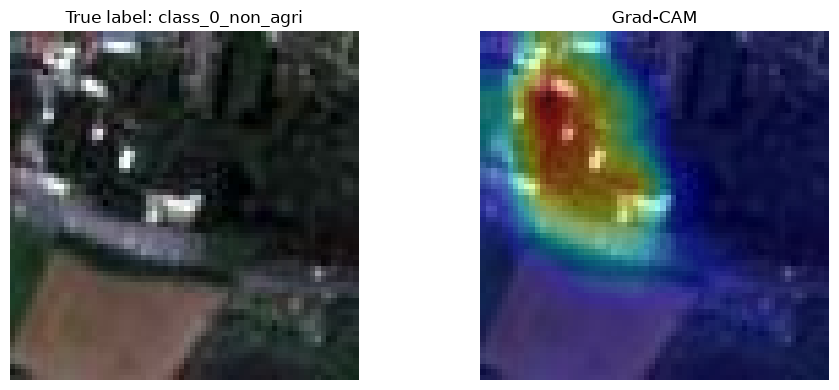

In [17]:
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    size=(64, 64)
).numpy().squeeze()


fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image_unnormalized)
axes[0].set_title(f"True label: {class_names[labels[0].numpy()]}")

axes[1].imshow(image_unnormalized)
axes[1].imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[1].set_title("Grad-CAM")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()